# Analisis Sentimen Ulasan Gojek (Google Play Store)

Tiga kelas: **positif, netral, negatif**. Data hasil scraping sendiri (`scraping.py`), pelabelan dengan model sentimen IndoRoBERTa,
tiga skema pelatihan deep learning, lalu inferensi.

In [1]:
import os, re
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## 1. Memuat data

In [2]:
DATA_PATH = "dataset_ulasan_gojek.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(17352, 5)


,reviewId,ulasan,rating,thumbsUpCount,tanggal
0,d2b5a1fb-4ec9-414d-b408-36127ded60b3,ke mana mau kirim email ? mau chat customer se...,1,0,2026-11-03 16:45:30
1,71cf048b-cfae-4c4f-aaad-a1d4732bbac6,tidak ada derefer,1,0,2026-11-03 16:36:44
2,4104c164-29b4-4d7e-9f21-ad68fd2ef2c2,maaf kalo omongan gua kasar atau gua ga paham ...,1,0,2026-11-03 14:53:30
3,ac534dcc-22ca-413d-90e2-f7a3cf4fef86,Ngapain ngasih promo ongkir murah TPI ga perna...,1,0,2026-11-03 14:15:04
4,1ca3253f-ffba-4efe-bd9d-c763cdb51869,notif nya sangad menganggu sekali,1,0,2026-11-03 14:01:11


In [3]:
print("Ulasan kosong:", df["ulasan"].isna().sum(), "| duplikat:", df["ulasan"].duplicated().sum())
print(df["rating"].value_counts().sort_index())

Ulasan kosong: 0 | duplikat: 0
rating
1    3965
2    3971
3    3864
4    3040
5    2512
Name: count, dtype: int64


## 2. Pembersihan teks

Lowercase, hapus URL/angka/simbol, rapikan huruf berulang ("bagusss" -> "bagus"), normalisasi kata gaul.
Stopword **tidak dibuang** karena label berasal dari model yang membaca teks utuh; kata seperti "sih", "kok", "masih" sering menentukan nuansa.

In [4]:
SLANG = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "nggak": "tidak", "ngga": "tidak", "enggak": "tidak",
    "tdk": "tidak", "tak": "tidak", "g": "tidak", "yg": "yang", "dgn": "dengan", "udh": "sudah",
    "udah": "sudah", "sdh": "sudah", "blm": "belum", "bgt": "banget", "bngt": "banget", "bnyk": "banyak",
    "jg": "juga", "aja": "saja", "tp": "tapi", "tpi": "tapi", "krn": "karena", "karna": "karena",
    "trs": "terus", "sy": "saya", "dr": "dari", "utk": "untuk", "bgs": "bagus", "jlk": "jelek",
    "lemot": "lambat", "lelet": "lambat", "ngelag": "lag", "driver": "pengemudi", "mantul": "mantap",
    "oke": "baik", "ok": "baik", "thx": "terima kasih", "makasih": "terima kasih", "trims": "terima kasih",
    "dpt": "dapat", "dapet": "dapat", "kyk": "seperti", "kayak": "seperti", "emg": "memang", "sm": "sama",
    "lg": "lagi", "skrg": "sekarang", "bs": "bisa", "bsa": "bisa", "mksh": "terima kasih",
}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    tokens = [SLANG.get(t, t) for t in text.split()]
    tokens = [t for t in tokens if len(t) > 1]
    return " ".join(tokens)

df["teks_bersih"] = df["ulasan"].apply(clean_text)
df = df[df["teks_bersih"].str.strip() != ""].drop_duplicates(subset="teks_bersih").reset_index(drop=True)
print("Jumlah data setelah pembersihan:", len(df))
df[["ulasan", "teks_bersih"]].sample(5, random_state=SEED)

Jumlah data setelah pembersihan: 16821


,ulasan,teks_bersih
5834,setelah 2x update terakhir kok malah aplikasi ...,setelah update terakhir kok malah aplikasi jad...
6632,Gosend knapa sekarang tidak ada fitur Chat nya...,gosend knapa sekarang tidak ada fitur chat nya...
7168,"Driver nya pilih"" kalo murah di up klo mahal d...",pengemudi nya pilih kalo murah di up klo mahal...
6505,susah ganti pin karna nomer gopay sudah nonakt...,susah ganti pin karena nomer gopay sudah nonak...
5639,"dapet notif terlalu banyak cancle, trus akun b...",dapat notif terlalu banyak cancle trus akun ba...


## 3. Pelabelan (model sentimen IndoRoBERTa)

Label diberikan oleh model sentimen berbahasa Indonesia yang sudah dilatih (`w11wo/indonesian-roberta-base-sentiment-classifier`),
dibaca dari teks asli ulasan (bukan teks yang sudah distem/dibersihkan). Prediksi dengan keyakinan rendah (ambang per kelas) dan ulasan
yang ratingnya jelas bertentangan dengan label (rating 5 berlabel negatif, rating 1-2 berlabel positif) dibuang supaya label tidak terlalu noisy. Rating bintang **tidak** dipakai sebagai label, hanya untuk sanity check.

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/328 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/808k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/467k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Label mentah dari model: {'negative': 12469, 'positive': 3241, 'neutral': 1111}
Dibuang: 3365 keyakinan rendah, 363 kontradiksi rating
Data dipertahankan: 13093 dari 16821
label
negatif    10332
positif     2059
netral       702
Name: count, dtype: int64


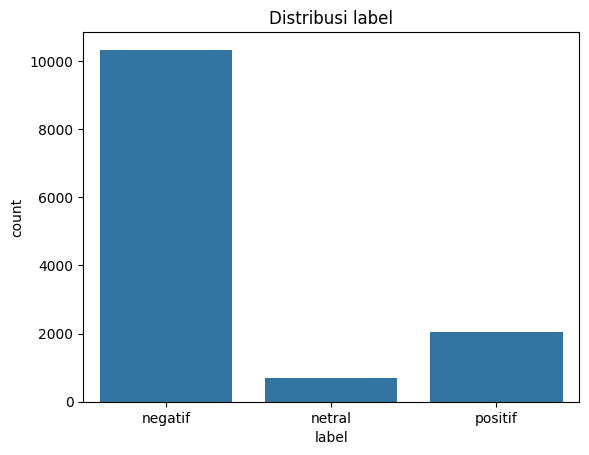

In [5]:
import torch
from transformers import pipeline

MODEL_LABEL = "w11wo/indonesian-roberta-base-sentiment-classifier"
THRESHOLD = {"negatif": 0.90, "positif": 0.90, "netral": 0.70}   # ambang keyakinan per kelas

clf = pipeline("text-classification", model=MODEL_LABEL, device=0 if torch.cuda.is_available() else -1)
hasil = clf(df["ulasan"].astype(str).tolist(), batch_size=64, truncation=True, max_length=128)

df["label_model"] = [h["label"].lower() for h in hasil]
df["conf"] = [h["score"] for h in hasil]
print("Label mentah dari model:", df["label_model"].value_counts().to_dict())

PETA = {"positive": "positif", "neutral": "netral", "negative": "negatif"}
df["label"] = df["label_model"].map(PETA)
assert df["label"].notna().all(), f"Label tak dikenal: {set(df['label_model']) - set(PETA)}"

sebelum = len(df)
lolos = df["conf"] >= df["label"].map(THRESHOLD)
# rating ekstrem yang bertentangan dengan label model dianggap noise
kontradiksi = ((df["rating"] == 5) & (df["label"] == "negatif")) | ((df["rating"] <= 2) & (df["label"] == "positif"))
print(f"Dibuang: {(~lolos).sum()} keyakinan rendah, {(lolos & kontradiksi).sum()} kontradiksi rating")
df = df[lolos & ~kontradiksi].reset_index(drop=True)
print(f"Data dipertahankan: {len(df)} dari {sebelum}")
if len(df) < 10000:
    print("PERINGATAN: data < 10.000. Turunkan THRESHOLD negatif/positif (mis. 0.85) atau scraping lebih banyak.")
print(df["label"].value_counts())
sns.countplot(data=df, x="label", order=["negatif", "netral", "positif"])
plt.title("Distribusi label"); plt.show()

In [6]:
# Sanity check: rating bintang vs label model (harusnya rating 1-2 dominan negatif, 4-5 dominan positif)
pd.crosstab(df["rating"], df["label"], normalize="index").round(2)

label,negatif,netral,positif
rating,,,
1,0.97,0.03,0.00
2,0.97,0.03,0.00
3,0.90,0.05,0.05
4,0.52,0.11,0.37
5,0.00,0.11,0.89


In [7]:
df.to_csv("dataset_berlabel.csv", index=False)
le = LabelEncoder()
y = le.fit_transform(df["label"])
print(dict(zip(le.classes_, le.transform(le.classes_))))

{'negatif': np.int64(0), 'netral': np.int64(1), 'positif': np.int64(2)}


## 4. Ekstraksi fitur & model

Dua cara ekstraksi fitur:
- **Urutan token** (vocab -> indeks -> padding) untuk Bi-LSTM dan CNN 1D, dengan embedding yang dilatih sendiri.
- **TF-IDF** (unigram + bigram) untuk MLP.

Vocab dan TF-IDF hanya di-*fit* pada data latih supaya tidak ada kebocoran ke data uji.

In [8]:
MAX_WORDS = 20000
panjang = df["teks_bersih"].str.split().str.len()
MAXLEN = int(min(np.percentile(panjang, 95), 100))
print("MAXLEN:", MAXLEN)

class Vocab:
    def __init__(self, max_words):
        self.max_words = max_words
    def fit(self, texts):
        c = Counter(t for s in texts for t in s.split())
        self.w2i = {w: i + 2 for i, (w, _) in enumerate(c.most_common(self.max_words - 2))}  # 0=pad, 1=OOV
        return self
    def encode(self, texts, maxlen):
        out = np.zeros((len(texts), maxlen), dtype="int32")
        for i, s in enumerate(texts):
            ids = [self.w2i.get(t, 1) for t in s.split()][:maxlen]
            out[i, :len(ids)] = ids
        return out

def feat_seq(tr, te):
    v = Vocab(MAX_WORDS).fit(tr)
    return v.encode(tr, MAXLEN), v.encode(te, MAXLEN), (lambda t: v.encode(t, MAXLEN))

def feat_tfidf(tr, te):
    tfv = TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    A = tfv.fit_transform(tr).toarray().astype("float32")
    B = tfv.transform(te).toarray().astype("float32")
    return A, B, (lambda t: tfv.transform(t).toarray().astype("float32"))

MAXLEN: 63


In [9]:
def build_bilstm(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Embedding(MAX_WORDS, 128, mask_zero=True),
        layers.SpatialDropout1D(0.3),
        layers.Bidirectional(layers.LSTM(64)),
        layers.Dropout(0.4),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(3, activation="softmax"),
    ])

def build_mlp(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(3, activation="softmax"),
    ])

def build_cnn(input_shape):
    inp = layers.Input(shape=input_shape)
    x = layers.Embedding(MAX_WORDS, 128)(inp)
    x = layers.SpatialDropout1D(0.2)(x)
    pools = [layers.GlobalMaxPooling1D()(layers.Conv1D(128, k, activation="relu")(x)) for k in (3, 4, 5)]
    x = layers.Concatenate()(pools)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(3, activation="softmax")(x)
    return models.Model(inp, out)

In [10]:
results = []

def plot_history(h, nama):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h.history["accuracy"], label="train"); ax[0].plot(h.history["val_accuracy"], label="val")
    ax[0].set_title(f"{nama} - akurasi"); ax[0].legend()
    ax[1].plot(h.history["loss"], label="train"); ax[1].plot(h.history["val_loss"], label="val")
    ax[1].set_title(f"{nama} - loss"); ax[1].legend()
    plt.tight_layout(); plt.show()

def jalankan_skema(nama, build_fn, featurize, test_size, epochs=20, batch=64,
                   monitor="val_loss", patience=3, lr_decay=False):
    X_tr_txt, X_te_txt, y_tr, y_te = train_test_split(
        df["teks_bersih"].tolist(), y, test_size=test_size, stratify=y, random_state=SEED)
    X_tr, X_te, transform = featurize(X_tr_txt, X_te_txt)

    model = build_fn(X_tr.shape[1:])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [callbacks.EarlyStopping(monitor=monitor, patience=patience, restore_best_weights=True)]
    if lr_decay:
        cb.append(callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5))
    h = model.fit(X_tr, y_tr, validation_split=0.1, epochs=epochs, batch_size=batch,
                  callbacks=cb, verbose=2)

    train_acc = model.evaluate(X_tr, y_tr, verbose=0)[1]
    test_acc = model.evaluate(X_te, y_te, verbose=0)[1]
    pred = model.predict(X_te, verbose=0).argmax(1)

    print(f"\n[{nama}] train acc = {train_acc:.4f} | test acc = {test_acc:.4f}")
    print(classification_report(y_te, pred, target_names=le.classes_, digits=4))
    plot_history(h, nama)
    sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion matrix - {nama}"); plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.show()

    results.append(dict(nama=nama, model=model, transform=transform, train_acc=train_acc, test_acc=test_acc,
                        f1_macro=f1_score(y_te, pred, average="macro")))

### Skema 1 - Bi-LSTM + urutan token, split 80/20

Epoch 1/30
148/148 - 9s - 62ms/step - accuracy: 0.8573 - loss: 0.4257 - val_accuracy: 0.9151 - val_loss: 0.2413 - learning_rate: 0.0010
Epoch 2/30
148/148 - 2s - 15ms/step - accuracy: 0.9276 - loss: 0.1961 - val_accuracy: 0.9227 - val_loss: 0.2149 - learning_rate: 0.0010
Epoch 3/30
148/148 - 3s - 18ms/step - accuracy: 0.9622 - loss: 0.1206 - val_accuracy: 0.9313 - val_loss: 0.1929 - learning_rate: 0.0010
Epoch 4/30
148/148 - 2s - 13ms/step - accuracy: 0.9796 - loss: 0.0679 - val_accuracy: 0.9361 - val_loss: 0.2092 - learning_rate: 0.0010
Epoch 5/30
148/148 - 2s - 13ms/step - accuracy: 0.9883 - loss: 0.0390 - val_accuracy: 0.9418 - val_loss: 0.2594 - learning_rate: 5.0000e-04
Epoch 6/30
148/148 - 2s - 13ms/step - accuracy: 0.9923 - loss: 0.0286 - val_accuracy: 0.9342 - val_loss: 0.2579 - learning_rate: 2.5000e-04
Epoch 7/30
148/148 - 2s - 13ms/step - accuracy: 0.9938 - loss: 0.0257 - val_accuracy: 0.9370 - val_loss: 0.2728 - learning_rate: 1.2500e-04
Epoch 8/30
148/148 - 2s - 14ms/step 

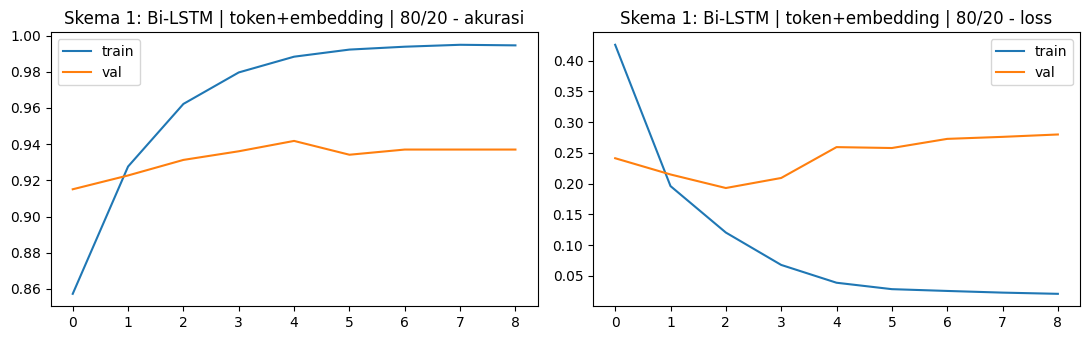

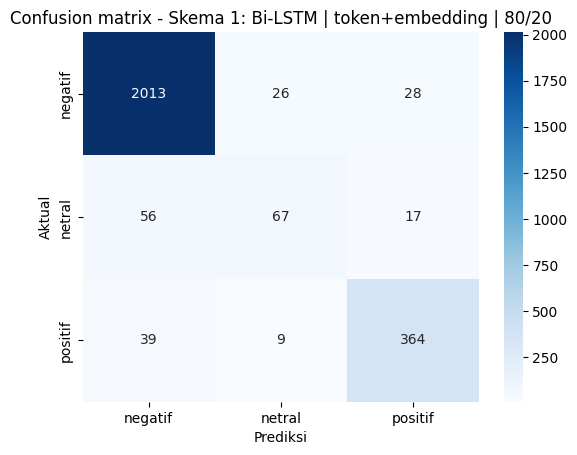

In [11]:
jalankan_skema("Skema 1: Bi-LSTM | token+embedding | 80/20", build_bilstm, feat_seq, test_size=0.2,
               epochs=30, monitor="val_accuracy", patience=4, lr_decay=True)

### Skema 2 - MLP + TF-IDF (1-2 gram), split 80/20

Epoch 1/20
148/148 - 8s - 53ms/step - accuracy: 0.8427 - loss: 0.4567 - val_accuracy: 0.9094 - val_loss: 0.2428
Epoch 2/20
148/148 - 1s - 4ms/step - accuracy: 0.9292 - loss: 0.1839 - val_accuracy: 0.9275 - val_loss: 0.1821
Epoch 3/20
148/148 - 1s - 4ms/step - accuracy: 0.9669 - loss: 0.0956 - val_accuracy: 0.9332 - val_loss: 0.1836
Epoch 4/20
148/148 - 1s - 4ms/step - accuracy: 0.9808 - loss: 0.0592 - val_accuracy: 0.9332 - val_loss: 0.1946
Epoch 5/20
148/148 - 1s - 4ms/step - accuracy: 0.9865 - loss: 0.0411 - val_accuracy: 0.9284 - val_loss: 0.2165

[Skema 2: MLP | TF-IDF | 80/20] train acc = 0.9657 | test acc = 0.9267
              precision    recall  f1-score   support

     negatif     0.9474    0.9763    0.9616      2067
      netral     0.6076    0.3429    0.4384       140
     positif     0.8805    0.8762    0.8783       412

    accuracy                         0.9267      2619
   macro avg     0.8118    0.7318    0.7594      2619
weighted avg     0.9187    0.9267    0.9206   

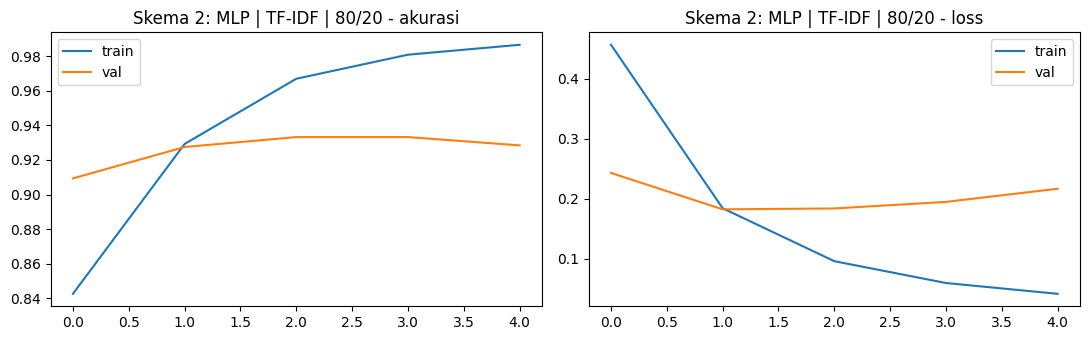

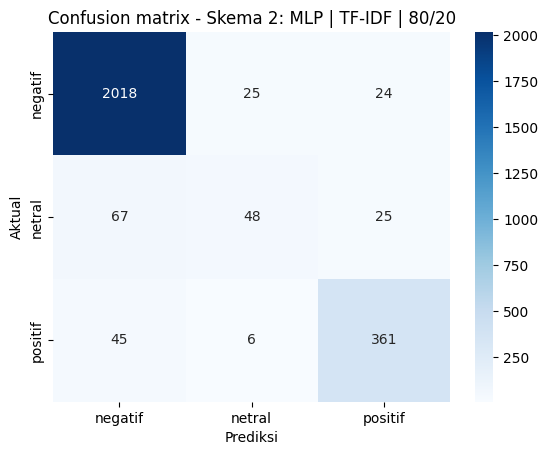

In [12]:
jalankan_skema("Skema 2: MLP | TF-IDF | 80/20", build_mlp, feat_tfidf, test_size=0.2)

### Skema 3 - CNN 1D + urutan token, split 70/30

Epoch 1/30
129/129 - 23s - 177ms/step - accuracy: 0.8401 - loss: 0.4421 - val_accuracy: 0.9040 - val_loss: 0.2750 - learning_rate: 0.0010
Epoch 2/30
129/129 - 1s - 6ms/step - accuracy: 0.9208 - loss: 0.2121 - val_accuracy: 0.9029 - val_loss: 0.2440 - learning_rate: 0.0010
Epoch 3/30
129/129 - 1s - 5ms/step - accuracy: 0.9601 - loss: 0.1273 - val_accuracy: 0.9193 - val_loss: 0.2448 - learning_rate: 0.0010
Epoch 4/30
129/129 - 1s - 5ms/step - accuracy: 0.9819 - loss: 0.0632 - val_accuracy: 0.9215 - val_loss: 0.2646 - learning_rate: 5.0000e-04
Epoch 5/30
129/129 - 1s - 5ms/step - accuracy: 0.9881 - loss: 0.0423 - val_accuracy: 0.9226 - val_loss: 0.2674 - learning_rate: 2.5000e-04
Epoch 6/30
129/129 - 1s - 5ms/step - accuracy: 0.9916 - loss: 0.0336 - val_accuracy: 0.9226 - val_loss: 0.2801 - learning_rate: 1.2500e-04
Epoch 7/30
129/129 - 1s - 6ms/step - accuracy: 0.9927 - loss: 0.0297 - val_accuracy: 0.9237 - val_loss: 0.2908 - learning_rate: 6.2500e-05
Epoch 8/30
129/129 - 1s - 7ms/step -

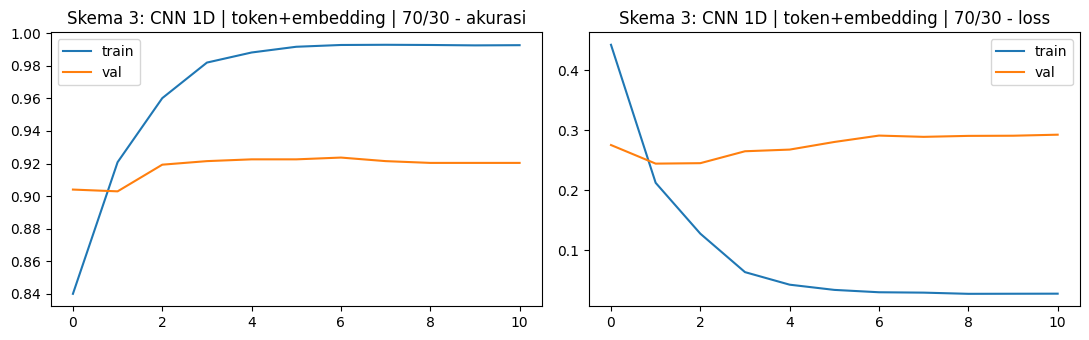

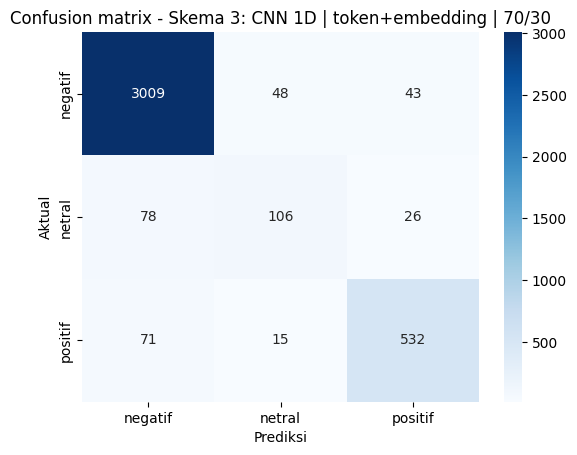

In [13]:
jalankan_skema("Skema 3: CNN 1D | token+embedding | 70/30", build_cnn, feat_seq, test_size=0.3,
               epochs=30, monitor="val_accuracy", patience=4, lr_decay=True)

## 5. Perbandingan skema

Catatan: kelas tidak seimbang (negatif paling banyak, netral paling sedikit), jadi `f1_macro` dilaporkan di samping akurasi.

In [14]:
ringkasan = pd.DataFrame([{k: r[k] for k in ["nama", "train_acc", "test_acc", "f1_macro"]} for r in results])
ringkasan["lolos_>92%"] = (ringkasan["train_acc"] > 0.92) & (ringkasan["test_acc"] > 0.92)
ringkasan.round(4)

,nama,train_acc,test_acc,f1_macro,lolos_>92%
0,Skema 1: Bi-LSTM | token+embedding | 80/20,0.9892,0.9332,0.8016,True
1,Skema 2: MLP | TF-IDF | 80/20,0.9657,0.9267,0.7594,True
2,Skema 3: CNN 1D | token+embedding | 70/30,0.9892,0.9285,0.7980,True


## 6. Inferensi

Pakai skema dengan akurasi uji tertinggi. Output berupa kelas kategorikal: negatif / netral / positif.

In [15]:
terbaik = max(results, key=lambda r: r["test_acc"])
print("Model untuk inferensi:", terbaik["nama"])

def prediksi_sentimen(daftar_teks):
    bersih = [clean_text(t) for t in daftar_teks]
    proba = terbaik["model"].predict(terbaik["transform"](bersih), verbose=0)
    for teks, p in zip(daftar_teks, proba):
        print(f"{le.classes_[p.argmax()].upper():8s} ({p.max():.2f})  <-  {teks}")

contoh = [
    "Aplikasinya bagus banget, pengemudi ramah dan pesanan cepat sampai",
    "Parah, pesanan dibatalkan sepihak dan saldo tidak kembali, sangat mengecewakan",
    "Aplikasi untuk memesan ojek, makanan, dan kirim barang",
    "Tidak bagus, sering error dan lambat",
    "Promo banyak, sangat membantu setiap hari",
    "Pengemudinya tidak datang-datang, customer service tidak membantu",
]
prediksi_sentimen(contoh)

Model untuk inferensi: Skema 1: Bi-LSTM | token+embedding | 80/20
POSITIF  (1.00)  <-  Aplikasinya bagus banget, pengemudi ramah dan pesanan cepat sampai
NEGATIF  (1.00)  <-  Parah, pesanan dibatalkan sepihak dan saldo tidak kembali, sangat mengecewakan
NETRAL   (0.97)  <-  Aplikasi untuk memesan ojek, makanan, dan kirim barang
NEGATIF  (1.00)  <-  Tidak bagus, sering error dan lambat
POSITIF  (1.00)  <-  Promo banyak, sangat membantu setiap hari
NEGATIF  (1.00)  <-  Pengemudinya tidak datang-datang, customer service tidak membantu


In [16]:
terbaik["model"].save("model_sentimen_terbaik.keras")